## ISOM4030 Lab 2.3 - Python Revision: Matplotlib

#### Part II: Visualization - Matplotlib

In [1]:
# To print multiple outputs for one cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

In [2]:
# If you want to enable matplotlib's interactive features,
# install jupyter-matplotlib (a.k.a. ipympl) via pip or conda.
! pip install ipympl --quiet

#### Restart runtime to continue.

In [3]:
from google.colab import output
output.enable_custom_widget_manager()

# Enable the widget backend.

%matplotlib widget



[Matplotlib](https://matplotlib.org/) is a data visualization library built on NumPy arrays, and works as the foundation for more advanced data visualization libraries in the Python data analytics stack.

<img src="https://drive.google.com/uc?export=download&id=1Lj3H-j_nGLPsBqi-Jq4IgdUUk78WxQon"  width="300px"></img>



In [4]:
import numpy as np
from numpy.random import default_rng
import matplotlib as mpl
import matplotlib.pyplot as plt   # The plt interface is what we will use most often

print(f"Version number: {mpl.__version__}")

Version number: 3.10.0


---

<br>

#### Object-Oriented Interface


The plotting functions are methods of explicit `Figure` and `Axes` objects.




In [5]:
# under the hood, line plots are created by connecting a set of (invisible) points
# So we first generate a sequence of x coordinates for them using np.linspace()
x = np.linspace(0, 4, 50)

[Text(0.5, 0, 'x label'),
 Text(0, 0.5, 'y label'),
 Text(0.5, 1.0, 'Simple Plot')]

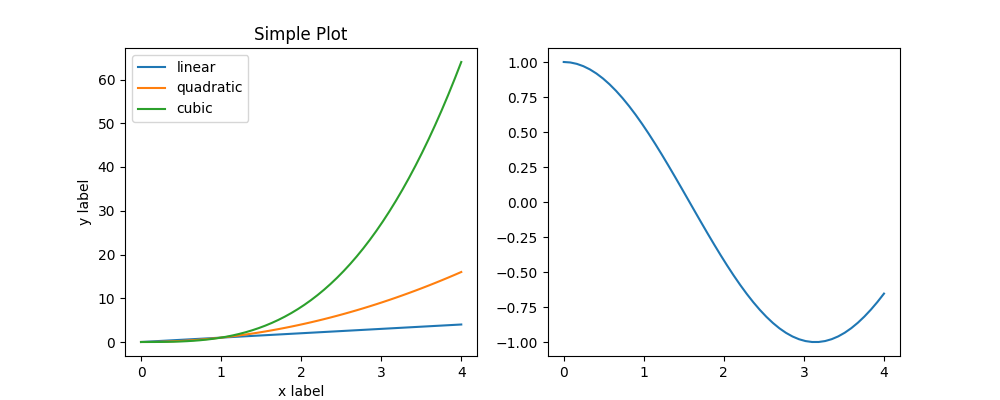

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Call plot() method on the appropriate object

ax[0].plot(x, x, label='linear')
ax[0].plot(x, x**2, label='quadratic')
ax[0].plot(x, x**3, label='cubic')
ax[1].plot(x, np.cos(x))

ax[0].set(xlabel='x label', ylabel='y label', title="Simple Plot")
ax[0].legend()
plt.show()

#### Parts of a Plot


A matplotlib plot can be understood from an object-oriented perspective:

<img src="https://drive.google.com/uc?export=download&id=1fOcU6bDPAfgXBsbcNX8pu5NH5J9BO121"  width="350px" style="float: left; margin-bottom: 1.5em; margin-top: 1.5em; margin-right: 10%;"/></img>


<br>


 Plots reside within a [`Figure`](https://matplotlib.org/api/_as_gen/matplotlib.figure.Figure.html) instance, which can be thought of as a single container that contains all the objects representing axes, graphics, text, and labels.


An [`Axes`](https://matplotlib.org/api/axes_api.html#matplotlib.axes.Axes) is a bounding box with ticks and labels, which will eventually contain the plot elements that make up our visualization.



Everything else is an [`Artist`](https://matplotlib.org/api/artist_api.html), including `Text` objects, `Line2D` objects, collection objects, `Patch` objects, ... .


Most `Artist`s are tied to an `Axes`. When the figure is rendered, all of the artists are drawn to the canvas.


<br>



<div class="alert alert-info">Here are the full set of <a herf="https://matplotlib.org/3.1.1/api/colors_api.html">colors, <a herf="https://matplotlib.org/api/markers_api.html">markers</a>, <a herf="https://matplotlib.org/api/_as_gen/matplotlib.lines.Line2D.html#matplotlib.lines.Line2D.set_linestyle">linestyles</a> supported by matplotlib.</div>



<div class="alert alert-info"><a href="https://matplotlib.org/api/axes_api.html">Axes.tick_params</a> can change the appearance of ticks, tick labels, and gridlines.</div>




---

<br>


#### Specialized Plots


There are many specialized plots we can create, such as barplots, histograms, scatter plots, and many more.





(array([ 1.,  1.,  0.,  1.,  3.,  3.,  6.,  5.,  3., 12., 11., 11., 15.,
         9., 12.,  3.,  2.,  0.,  0.,  2.]),
 array([-2.71116248, -2.46971242, -2.22826236, -1.98681229, -1.74536223,
        -1.50391217, -1.26246211, -1.02101205, -0.77956199, -0.53811192,
        -0.29666186, -0.0552118 ,  0.18623826,  0.42768832,  0.66913838,
         0.91058845,  1.15203851,  1.39348857,  1.63493863,  1.87638869,
         2.11783876]),
 <BarContainer object of 20 artists>)

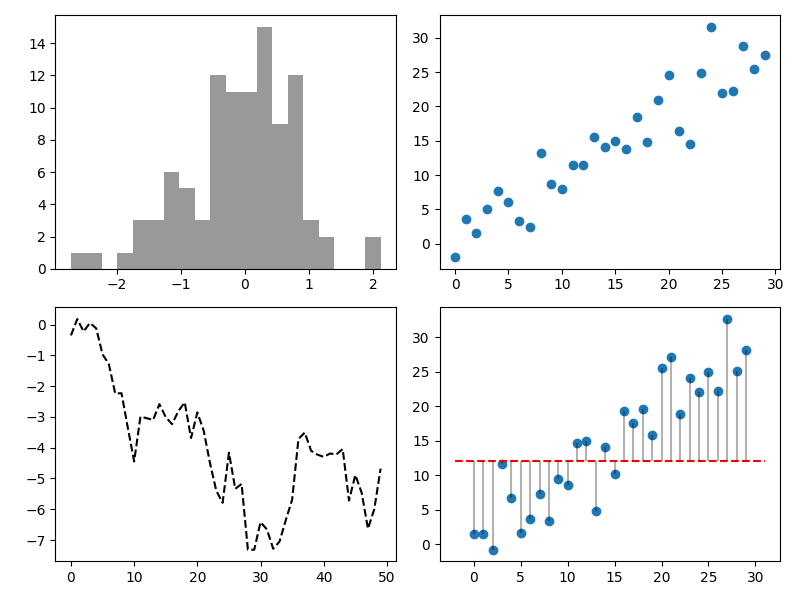

In [7]:
rng = default_rng(1)
fig, ax = plt.subplots(2, 2, figsize=(8, 6))

ax[0, 0].hist(rng.normal(size=100), bins=20, color='k', alpha=0.4)
ax[0, 1].scatter(np.arange(30), np.arange(30) + 3 * rng.normal(size=30))
ax[1, 0].plot(rng.normal(size=50).cumsum(), 'k--')

# plot the last panel
# plot data points using a scatter plot
x = np.arange(30)
y = np.arange(30) + 3 * rng.normal(size=30)
ax[1, 1].scatter(x, y)

# draw a straight line
x_eval = np.linspace(min(x)-2, max(x)+2, 200)
intercept = 12; slope = 0
ax[1, 1].plot(x_eval, intercept + x_eval * slope, 'r--')

# draw vertical bars that represent errors
ax[1, 1].vlines(x, intercept + x * slope, y, alpha=0.3, color="k")

plt.tight_layout()
plt.show()

In [8]:
# rng.normal(size=30) *3

In [9]:
# x,y


Here is an [overview](https://matplotlib.org/stable/plot_types/index.html) of some common plot types


**<font color='steelblue' > Question</font>**:

Given a Pandas' `DataFrame` that contains the information on sizes, numbers of bedrooms, and prices for 47 houses recently sold in the United States:

In [10]:
import pandas as pd

url = 'https://raw.githubusercontent.com/justinjiajia/datafiles/main/portland_housing_price_2f.csv'
pricing = pd.read_csv(url, names=["size", "no. of bedrooms", "price"])   # set the unnamed column as index when reading the file
pricing

,size,no. of bedrooms,price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900
5,1985,4,299900
6,1534,3,314900
7,1427,3,198999
8,1380,3,212000
9,1494,3,242500


Write code to fit 4 different straight lines to the data (their intercepts and slopes are given below) and generate a grid of panels that looks like the following (you don't have use the exact colors we use for different graphical elements):

<img src="housing_price_prediction.png" />

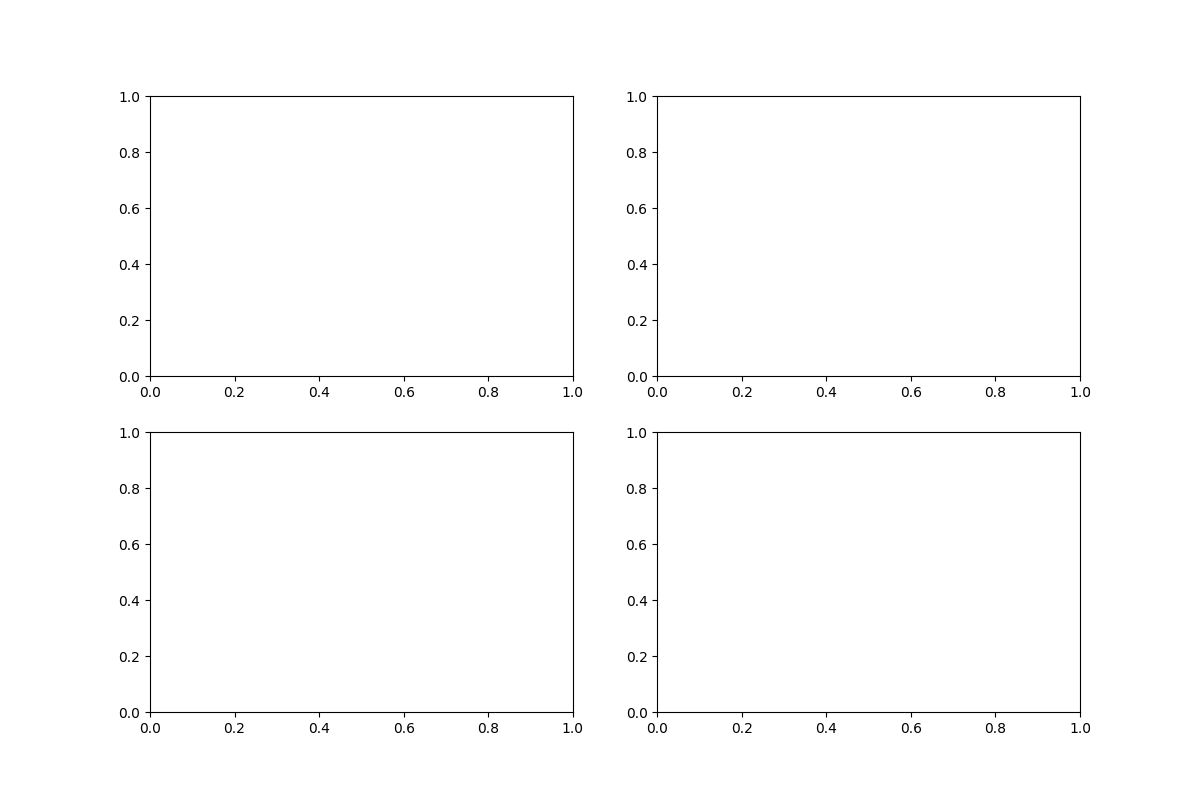

In [14]:
# starter code

x, y = pricing['size'].values/1000, pricing['price'].values/1000
x_eval = np.linspace(min(x)-0.2, max(x)+0.2, 50)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 4 sets of values for the parameters b and w
# each with the 1st element specifying the intercept and 2nd the slope
parameter_values =  [(150, 0), (200, 20), (71, 130), (0, 220)]



In [15]:
min(x), max(x)

(np.float64(0.852), np.float64(4.478))

[(0.2, 2.95), (50.0, 550.0)]

[(0.2, 2.95), (50.0, 550.0)]

[(0.2, 2.95), (50.0, 550.0)]

[(0.2, 2.95), (50.0, 550.0)]

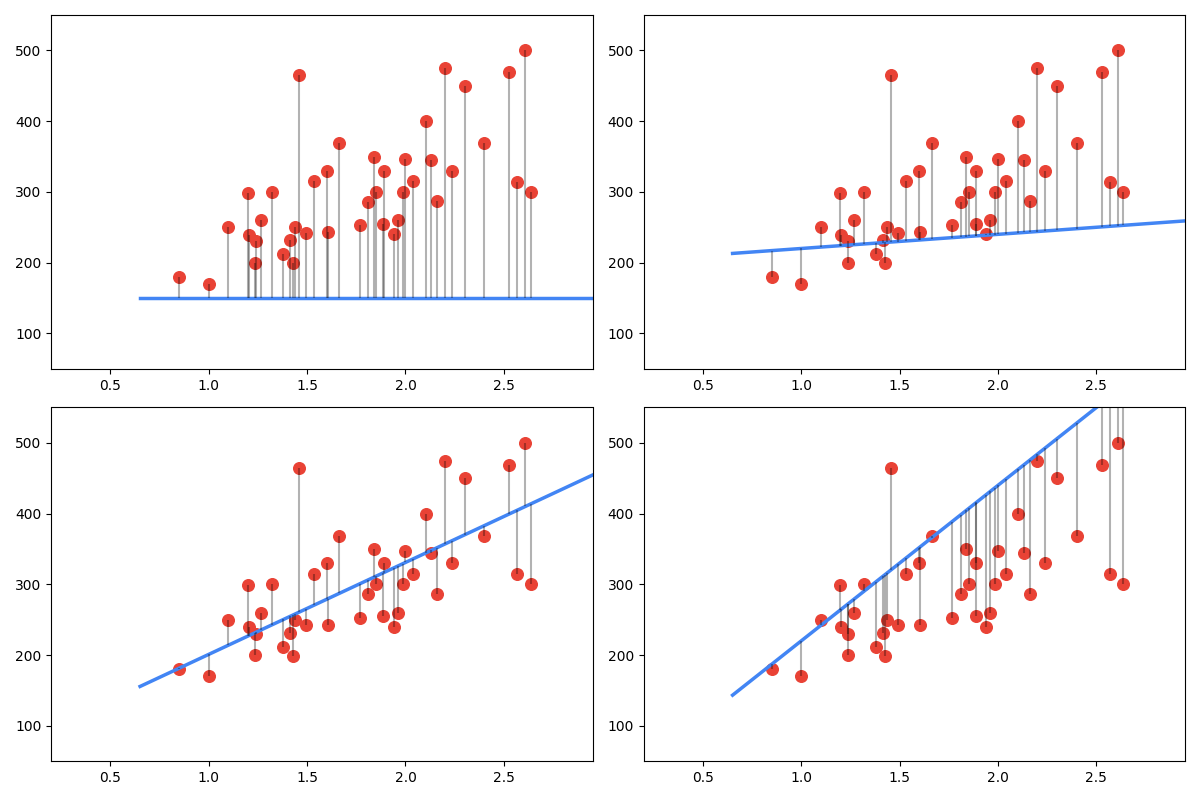

In [13]:
# provide your code below

for ax, (intercept, slope) in zip(axes.flat, [(150, 0), (200, 20), (71, 130), (0, 220)]):
    ax.________(____, _____, s=70, color=(233/255, 66/255, 53/255, 1), edgecolor=(233/255, 66/255, 53/255, 1))                      # draw training examples
    ax.________(___________, ______________________, color=(66/255, 133/255, 244/255, 1), linewidth=2.5)     # draw a straight line
    ax.________(____, ___________________, ____, alpha=0.3, color="k")      # draw vertical bars denoting residuals
    ax.set(xlim=(0.2, 2.95), ylim=(50, 550))
    #print(compute_cost(x, y, slope, intercept))

plt.tight_layout()
plt.show()
